# Customer Segmentation Using RFM Analysis

**Author:** Aidi Sara  ·    **Tools:** Python, pandas, seaborn

Using the UCI *Online Retail II* dataset, I segment ~4,300 customers by
**Recency**, **Frequency**, and **Monetary** value to identify who drives revenue
and who needs re-engagement. The main result: **21% of customers (Champions) generate
64% of revenue**, and a prioritized win-back list of 1,087 lapsed customers has been exported.

In [1]:
import os, glob, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="Set2")
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

N_QUANTILES   = 5
INACTIVE_PCTL = 0.75

preferred = "/kaggle/input/datasets/nathaniel/uci-online-retail-ii-data-set/online_retail_II.xlsx"
path = preferred if os.path.exists(preferred) else glob.glob(
    "/kaggle/input/**/online_retail_II.xlsx", recursive=True
)[0]

df = pd.read_excel(path)
print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
df.head()

Shape: 525,461 rows × 8 columns


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,"13,085.00",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,"13,085.00",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,"13,085.00",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,"13,085.00",United Kingdom


## Data Cleaning

The raw data needs a few standard filters before RFM makes sense:

- Remove rows without a `CustomerID` — RFM needs per-customer attribution.
- Remove duplicate line items.
- Drop cancellations (invoices starting with `C`) — these are returns, not purchases.
- Keep only positive quantities and prices.
- Create `Sales = Quantity × UnitPrice` for the Monetary metric.

Each step is logged below so the audit trail is transparent.

In [2]:

df = df.rename(columns={
    "Invoice"     : "InvoiceNo",
    "Price"       : "UnitPrice",
    "Customer ID" : "CustomerID",
})

required = ["InvoiceNo", "Quantity", "InvoiceDate", "UnitPrice", "CustomerID"]
missing  = [c for c in required if c not in df.columns]
assert not missing, f"Missing required columns: {missing}"

print("Columns standardized:", df.columns.tolist())

Columns standardized: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


In [3]:
raw_df = df.copy()     
df     = raw_df.copy()

# Ensure correct dtypes before cleaning
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
for c in ["Quantity", "UnitPrice", "CustomerID"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["InvoiceNo"] = df["InvoiceNo"].astype("string").str.strip()

log = []
def record(step, before, after, reason):
    log.append({"Step": step, "Before": before, "After": after, "Rows removed": before - after, "Reason": reason})

# 1) Drop missing essential values
b = len(df); df = df.dropna(subset=required).copy()
record("Drop missing essential values", b, len(df), "RFM requires attribution + timing")

# 2) Drop exact duplicates
b = len(df); df = df.drop_duplicates().copy()
record("Drop duplicates", b, len(df), "Duplicate line items")

# 3) Exclude cancellations
cancelled = df["InvoiceNo"].str.upper().str.startswith("C", na=False)
b = len(df); df = df.loc[~cancelled].copy()
record("Exclude cancellations (C-prefix)", b, len(df), "Returns, not purchases")

# 4) Exclude non-positive quantity / price
b = len(df); df = df.loc[(df["Quantity"] > 0) & (df["UnitPrice"] > 0)].copy()
record("Exclude non-positive qty/price", b, len(df), "Data errors")

# 5) Sales = Quantity × UnitPrice
df["Sales"] = df["Quantity"] * df["UnitPrice"]

# ─── Print cleaning log ────────────────────────────────────────────
log_df = pd.DataFrame(log)
log_df["Removed %"] = (log_df["Rows removed"] / raw_df.shape[0] * 100).round(2)
display(log_df)

print(f"\nRaw rows        : {len(raw_df):,}")
print(f"Cleaned rows    : {len(df):,}  ({len(df)/len(raw_df):.1%} retained)")
print(f"Unique customers: {df.CustomerID.nunique():,}")
print(f"Unique invoices : {df.InvoiceNo.nunique():,}")
print(f"Date range      : {df.InvoiceDate.min():%Y-%m-%d} → {df.InvoiceDate.max():%Y-%m-%d}")

,Step,Before,After,Rows removed,Reason,Removed %
0,Drop missing essential values,525461,417534,107927,RFM requires attribution + timing,20.54
1,Drop duplicates,417534,410763,6771,Duplicate line items,1.29
2,Exclude cancellations (C-prefix),410763,400947,9816,"Returns, not purchases",1.87
3,Exclude non-positive qty/price,400947,400916,31,Data errors,0.01



Raw rows        : 525,461
Cleaned rows    : 400,916  (76.3% retained)
Unique customers: 4,312
Unique invoices : 19,213
Date range      : 2009-12-01 → 2010-12-09


## RFM Metrics

For each customer I compute:

- **Recency** — days since their last purchase (smaller is better)
- **Frequency** — number of distinct invoices
- **Monetary** — total positive sales

The reference date is the day after the last transaction in the data, so the freshest
customer has recency = 1. Recency is therefore *relative to this snapshot*, not to
today's calendar.

In [4]:
reference_date = df["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = (
    df.groupby("CustomerID")
      .agg(
          Recency   = ("InvoiceDate", lambda s: (reference_date - s.max().normalize()).days),
          Frequency = ("InvoiceNo",   "nunique"),
          Monetary  = ("Sales",       "sum"),
      )
      .reset_index()
)

print(f"Reference date: {reference_date:%Y-%m-%d}")
print(f"Customers: {len(rfm):,}")
rfm.describe().round(2)

Reference date: 2010-12-10
Customers: 4,312


,CustomerID,Recency,Frequency,Monetary
count,"4,312.00","4,312.00","4,312.00","4,312.00"
mean,"15,349.29",91.17,4.46,"2,040.41"
std,"1,701.20",96.86,8.17,"8,911.76"
min,"12,346.00",1.00,1.00,2.95
25%,"13,882.50",18.00,1.00,307.19
50%,"15,350.50",53.00,2.00,701.62
75%,"16,834.25",136.00,5.00,"1,714.93"
max,"18,287.00",374.00,205.00,"349,164.35"


## Scoring & Segmentation

Each metric is binned into **quintiles** (5 groups of ~20%). This makes R, F, M
comparable despite their different scales:

- Recency: most recent quintile → **5**, least recent → **1**
- Frequency and Monetary: lowest quintile → **1**, highest → **5**

Customers are then grouped by rule:

| Segment | Rule |
|---|---|
| Champions | R≥4, F≥4, M≥4 |
| Loyal Customers | R≥3, F≥4 |
| Potential Loyalists | R≥4, F≥2 |
| New Customers | R≥4, F<2 |
| At Risk | R≤2, F≥3 |
| Hibernating | R≤2, F<3 |
| Big Spenders | M≥4 (residual) |
| Others | everything else |

In [5]:
ranks = {c: rfm[c].rank(method="first") for c in ["Recency","Frequency","Monetary"]}
rfm["R_Score"] = pd.qcut(ranks["Recency"],   N_QUANTILES, labels=[5,4,3,2,1]).astype(int)
rfm["F_Score"] = pd.qcut(ranks["Frequency"], N_QUANTILES, labels=[1,2,3,4,5]).astype(int)
rfm["M_Score"] = pd.qcut(ranks["Monetary"],  N_QUANTILES, labels=[1,2,3,4,5]).astype(int)

rfm["RFM_Score"] = rfm[["R_Score","F_Score","M_Score"]].astype(str).agg("".join, axis=1)

def segment(row):
    R, F, M = row.R_Score, row.F_Score, row.M_Score
    if R>=4 and F>=4 and M>=4: return "Champions"
    if R>=3 and F>=4:          return "Loyal Customers"
    if R>=4 and F>=2:          return "Potential Loyalists"
    if R>=4:                   return "New Customers"
    if R<=2 and F>=3:          return "At Risk"
    if R<=2:                   return "Hibernating"
    if M>=4:                   return "Big Spenders"
    return "Others"

rfm["Segment"] = rfm.apply(segment, axis=1)

assert rfm.CustomerID.is_unique
assert rfm[["R_Score","F_Score","M_Score"]].apply(lambda s: s.between(1,5).all()).all()
print(" Scoring complete")
rfm.head()

 Scoring complete


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,"12,346.00",165,11,372.86,2,5,2,252,At Risk
1,"12,347.00",3,2,"1,323.32",5,2,4,524,Potential Loyalists
2,"12,348.00",74,1,222.16,2,1,1,211,Hibernating
3,"12,349.00",43,3,"2,671.14",3,3,5,335,Big Spenders
4,"12,351.00",11,1,300.93,5,1,2,512,New Customers


## Segment Overview

How many customers, how much revenue, and how the average RFM profile differs.
The chart below shows the crucial business asymmetry: **Champions are a small
minority of customers but the majority of revenue**.

,Customers,Revenue,Avg_Recency,Avg_Frequency,Cust %,Rev %
Segment,,,,,,
Champions,911,"5,647,910.00",13.30,11.70,21.10,64.20
At Risk,700,"1,060,864.30",147.70,3.80,16.20,12.10
Loyal Customers,488,"890,937.60",39.10,5.40,11.30,10.10
Hibernating,1025,"414,000.10",212.50,1.10,23.80,4.70
Potential Loyalists,509,"370,518.00",18.50,2.00,11.80,4.20
Big Spenders,98,"186,084.20",53.70,2.30,2.30,2.10
Others,449,"181,557.80",52.50,1.50,10.40,2.10
New Customers,132,"46,361.80",18.90,1.00,3.10,0.50


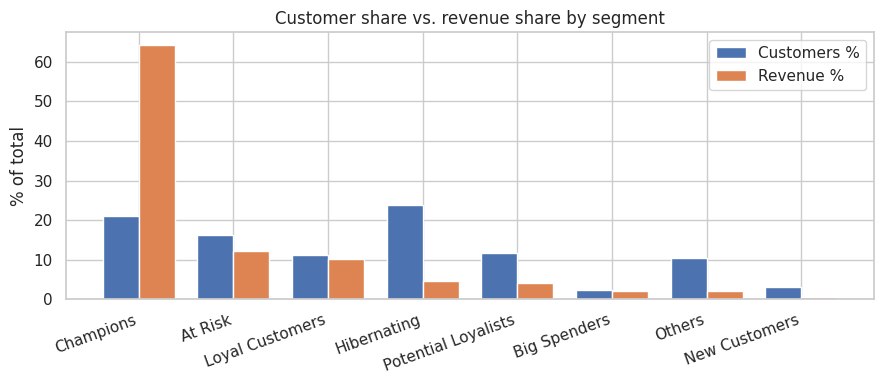

→ Champions: 21% of customers, 64% of revenue. Hibernating and Others combined are ~34% of customers but contribute <10% of revenue — cheap tactics only.


In [6]:
summary = (
    rfm.groupby("Segment")
       .agg(
           Customers     = ("CustomerID","nunique"),
           Revenue       = ("Monetary","sum"),
           Avg_Recency   = ("Recency","mean"),
           Avg_Frequency = ("Frequency","mean"),
       )
       .sort_values("Revenue", ascending=False)
       .round(1)
)
summary["Cust %"] = (summary.Customers / summary.Customers.sum() * 100).round(1)
summary["Rev %"]  = (summary.Revenue   / summary.Revenue.sum()   * 100).round(1)
display(summary)

plot = summary.reset_index()
fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(plot)); w = 0.38
ax.bar(x - w/2, plot["Cust %"], w, label="Customers %", color="#4C72B0")
ax.bar(x + w/2, plot["Rev %"],  w, label="Revenue %",   color="#DD8452")
ax.set_xticks(x); ax.set_xticklabels(plot.Segment, rotation=20, ha="right")
ax.set_ylabel("% of total"); ax.set_title("Customer share vs. revenue share by segment")
ax.legend()
plt.tight_layout(); plt.show()

print("→ Champions: 21% of customers, 64% of revenue. Hibernating and Others combined "
      "are ~34% of customers but contribute <10% of revenue — cheap tactics only.")

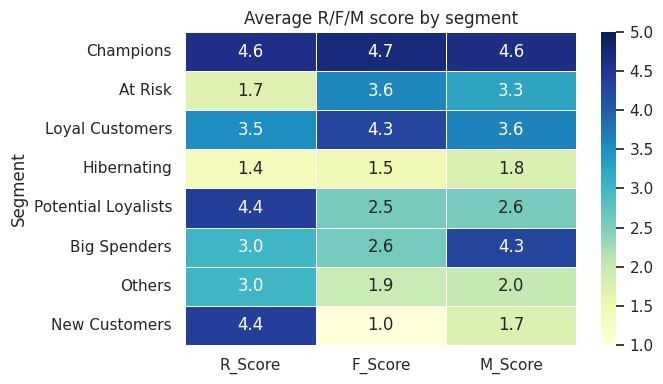

→ Champions average >4 on all three metrics; Hibernating averages <2 on R and F. The rules are producing the intended profiles.


In [7]:
heat = rfm.groupby("Segment")[["R_Score","F_Score","M_Score"]].mean().round(2).loc[summary.index]

plt.figure(figsize=(7, 4))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="YlGnBu", vmin=1, vmax=5, linewidths=.5)
plt.title("Average R/F/M score by segment")
plt.tight_layout(); plt.show()

print("→ Champions average >4 on all three metrics; Hibernating averages <2 on R and F. "
      "The rules are producing the intended profiles.")

## Marketing Recommendations

| Segment | Action |
|---|---|
| **Champions** | Loyalty rewards, early product access, referral program |
| **Loyal Customers** | Points-based loyalty tier, personalized recommendations |
| **Potential Loyalists** | Second-purchase incentive to push into Loyal |
| **New Customers** | Welcome series + first-repeat discount |
| **At Risk** | **High priority** — personalized win-back prioritized by prior spend |
| **Hibernating** | Low-cost bulk email only; avoid paid media |
| **Big Spenders** | Premium bundles, concierge service |
| **Others** | Broad campaigns; re-segment quarterly |

The single biggest lever here is retention, not acquisition: the **At-Risk + Big
Spender** spend (~$1.25M) exceeds the total revenue of Hibernating, New, and Others
combined. Concentrating budget on the top of that list is the highest-ROI move.

## Findings

- **Champions (21% of customers) drive 64% of revenue** — the concentrated base to protect.
- **Hibernating is the largest segment by count (24%) but only 5% of revenue** — low-cost reactivation only.
- **At-Risk (700 customers, $1.06M prior spend)** is the highest-value win-back opportunity.
- The **re-engagement threshold of 136 days** (75th percentile recency) gives a clean operational cutoff; 1,087 customers already exceed it.

## Limitations & Next Steps

- **Monetary is gross positive sales**, not profit. A COGS layer could reorder the segment ranking.
- **Recency is relative to the data snapshot**, not today — worth stating whenever the results are shared.
- **Rule-based thresholds** are pragmatic but arbitrary at the margins (F=3 vs F=4 is a soft cut).
- **Single snapshot** — no evidence that Champions stay Champions next quarter.

Worth doing next: (1) re-run quarterly to measure segment migration, (2) cross-check with K-Means on standardized RFM, (3) add a profitability layer if COGS data is available.